# Metamer-SAE — Notebook 04
## PCA baseline from natural-image observer activations

**Purpose:** fit one shared linear PCA representation using only pooled ConvNeXt-Tiny activations from the Imagenette training split, evaluate its reconstruction on the separate Imagenette validation split, and inspect only the Feather development triplets after component selection.

### Scope and guardrails

- Use the **pooled 384-dimensional activations** produced by Notebook 03.
- Fit PCA on `Imagenette train` only.
- Use `Imagenette validation` to assess reconstruction and choose a component-retention setting.
- Use the eight Feather development triplets only for a post-selection sanity check and visualization.
- Do **not** load or analyze the 32 primary-evaluation triplets or eight reserve triplets in this notebook.
- Do **not** fit a separate PCA for source, standard, or adversarial conditions.
- Do **not** use Feather images to fit PCA or any normalization parameters.
- Do **not** add human-behavioural or NSD analyses here.

Notebook 03's extraction arrays are assumed to exist in Google Drive. This notebook checks their paths, shapes, dtypes, metadata ordering, and finite values before fitting anything. It does not repeat image downloads or activation extraction.

**Important:** the PCA model is deliberately fitted without per-channel standardization and without whitening. Scikit-learn PCA centres features but does not scale each feature by default. This keeps the baseline tied to the covariance structure of the observer activations. Any scaled/whitened variant should be a separately labelled sensitivity analysis, not silently substituted for this baseline.

## 1. Mount Drive and configure project paths

The expected project root comes from the master handover: `/content/drive/MyDrive/metamer-sae`. If the folder is elsewhere, change `PROJECT_ROOT` below; do not move or recreate the existing data.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA

PROJECT_ROOT = Path('/content/drive/MyDrive/metamer-sae')

TRAIN_DIR = PROJECT_ROOT / 'activations' / 'natural_images' / 'train'
VAL_DIR = PROJECT_ROOT / 'activations' / 'natural_images' / 'validation'

TRAIN_ARRAY_PATH = TRAIN_DIR / 'pooled_activations.npy'
TRAIN_METADATA_PATH = TRAIN_DIR / 'metadata.csv'
VAL_ARRAY_PATH = VAL_DIR / 'pooled_activations.npy'
VAL_METADATA_PATH = VAL_DIR / 'metadata.csv'

FEATHER_DIRS = {
    'source': PROJECT_ROOT / 'activations' / 'feather' / 'source',
    'standard': PROJECT_ROOT / 'activations' / 'feather' / 'standard_resnet50',
    'adversarial': PROJECT_ROOT / 'activations' / 'feather' / 'adversarial_resnet50',
}

# A unique run folder prevents this notebook from silently overwriting older results.
RUN_ID = datetime.now(timezone.utc).strftime('pca_%Y%m%dT%H%M%SZ')
PCA_ROOT = PROJECT_ROOT / 'representations' / 'pca'
RUN_DIR = PCA_ROOT / 'runs' / RUN_ID
FIGURE_DIR = RUN_DIR / 'figures'

for directory in (RUN_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Run ID:', RUN_ID)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('PCA run directory:', RUN_DIR)

assert PROJECT_ROOT.is_dir(), f'Project root does not exist: {PROJECT_ROOT}'
for path in (TRAIN_ARRAY_PATH, TRAIN_METADATA_PATH, VAL_ARRAY_PATH, VAL_METADATA_PATH):
    assert path.is_file(), f'Missing Notebook 03 artifact: {path}'

print('\nPath check passed.')

Project root: /content/drive/MyDrive/metamer-sae
Run ID: pca_20261119T065920Z
Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
scikit-learn: 1.6.1
PCA run directory: /content/drive/MyDrive/metamer-sae/representations/pca/runs/pca_20261119T065920Z

Path check passed.


## 2. Load and verify natural-image activations

The activation arrays contain one 384-dimensional pooled vector per image. The arrays are opened as memory maps first, then copied into ordinary `float32` matrices for PCA. At this size, the training matrix is modest enough to fit exactly on the CPU.

The metadata checks below ensure that the training and validation rows have not been reordered or mixed. Dataset labels are retained for auditability but are not used to fit PCA.

In [ ]:
import json

EXPECTED_TRAIN_N = 9469
EXPECTED_VAL_N = 3925
EXPECTED_D = 384

train_map = np.load(TRAIN_ARRAY_PATH, mmap_mode='r', allow_pickle=False)
val_map = np.load(VAL_ARRAY_PATH, mmap_mode='r', allow_pickle=False)

# Load raw CSV files
train_meta_raw = pd.read_csv(TRAIN_METADATA_PATH)
val_meta_raw = pd.read_csv(VAL_METADATA_PATH)

# Parse nested JSON strings from 'metadata_json' column
train_meta = pd.json_normalize(train_meta_raw['metadata_json'].apply(json.loads))
val_meta = pd.json_normalize(val_meta_raw['metadata_json'].apply(json.loads))

# Fallback to copy sample_index as activation_index if not nested inside the JSON
if 'activation_index' not in train_meta.columns and 'sample_index' in train_meta_raw.columns:
    train_meta['activation_index'] = train_meta_raw['sample_index']
if 'activation_index' not in val_meta.columns and 'sample_index' in val_meta_raw.columns:
    val_meta['activation_index'] = val_meta_raw['sample_index']

assert train_map.shape == (EXPECTED_TRAIN_N, EXPECTED_D), train_map.shape
assert val_map.shape == (EXPECTED_VAL_N, EXPECTED_D), val_map.shape
assert train_map.dtype == np.float32, train_map.dtype
assert val_map.dtype == np.float32, val_map.dtype
assert len(train_meta) == EXPECTED_TRAIN_N
assert len(val_meta) == EXPECTED_VAL_N

required_metadata_columns = {'activation_index', 'split', 'filename', 'relative_path'}
assert required_metadata_columns.issubset(train_meta.columns), train_meta.columns.tolist()
assert required_metadata_columns.issubset(val_meta.columns), val_meta.columns.tolist()

assert train_meta['activation_index'].tolist() == list(range(EXPECTED_TRAIN_N))
assert val_meta['activation_index'].tolist() == list(range(EXPECTED_VAL_N))
assert set(train_meta['split'].astype(str).unique()) == {'train'}
assert set(val_meta['split'].astype(str).unique()).issubset({'val', 'validation'})
assert train_meta['filename'].is_unique
assert val_meta['filename'].is_unique
assert set(train_meta['filename']).isdisjoint(set(val_meta['filename']))

# Explicit copy to float32: PCA is the only operation in this notebook that fits a representation.
X_train = np.asarray(train_map, dtype=np.float32)
X_val = np.asarray(val_map, dtype=np.float32)

del train_map, val_map

assert np.isfinite(X_train).all(), 'Non-finite value found in training activations.'
assert np.isfinite(X_val).all(), 'Non-finite value found in validation activations.'

print('Training activations:', X_train.shape, X_train.dtype)
print('Validation activations:', X_val.shape, X_val.dtype)
print('Training split metadata:', train_meta['split'].value_counts().to_dict())
print('Validation split metadata:', val_meta['split'].value_counts().to_dict())
print('Train/validation filename overlap:', len(set(train_meta['filename']) & set(val_meta['filename'])))
print('\nNatural-image activation integrity checks passed.')

Training activations: (9469, 384) float32
Validation activations: (3925, 384) float32
Training split metadata: {'train': 9469}
Validation split metadata: {'val': 3925}
Train/validation filename overlap: 0

Natural-image activation integrity checks passed.


## 3. Inspect activation scale before choosing a representation

Notebook 03's pooled-value histogram showed a strongly concentrated central mass with a small number of large values. This is worth documenting because PCA is variance-driven. The diagnostics below report channel-wise scale and a sampled view of the pooled distribution.

**Decision for the primary baseline:** do not z-score each channel at this stage. Per-channel standardization would give low-variance channels equal variance to high-variance channels and would therefore change the metric being tested. PCA will centre each channel internally. If an alternative scaling is tested later, it must be trained from `Imagenette train` only and reported as a separate analysis.

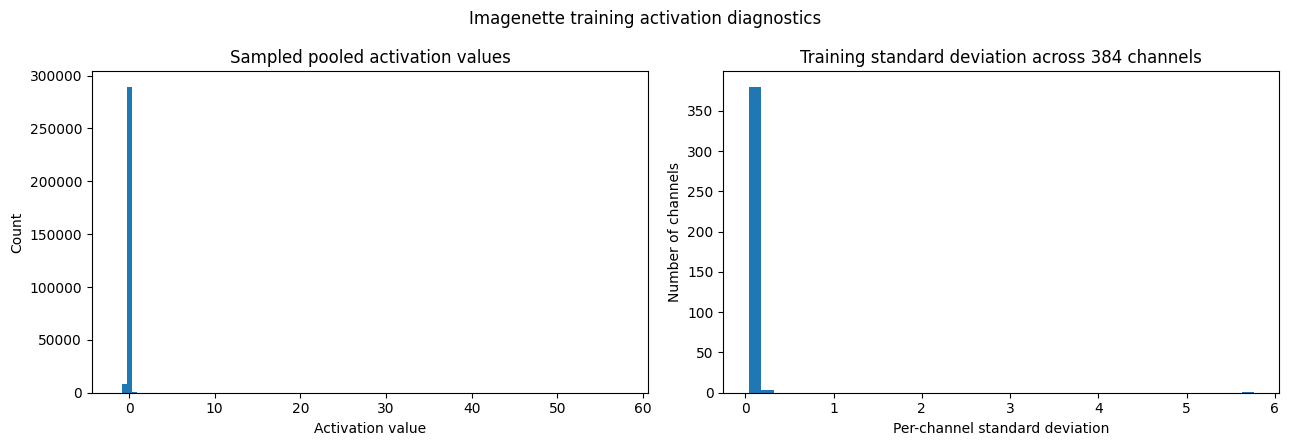

            mean        std        min        p01     median        p99  \
count  384.00000  384.00000  384.00000  384.00000  384.00000  384.00000   
mean     0.08894    0.09370   -0.27478   -0.12261    0.08641    0.31982   
std      1.84593    0.29159    1.24312    1.39417    1.78899    2.70023   
min     -0.51395    0.03678   -1.41925   -0.91165   -0.49618   -0.34755   
25%     -0.02519    0.06145   -0.37951   -0.22563   -0.02403    0.13959   
50%     -0.00198    0.07589   -0.31772   -0.17262   -0.00128    0.17272   
75%      0.01504    0.09022   -0.25515   -0.13713    0.01523    0.21285   
max     36.14637    5.76752   23.83940   27.04876   35.03073   53.06969   

             max  
count  384.00000  
mean     0.48702  
std      3.15393  
min     -0.26590  
25%      0.25578  
50%      0.31465  
75%      0.37748  
max     62.08433  

Saved feature statistics and activation diagnostic figure.


In [ ]:
rng = np.random.default_rng(42)
flat = X_train.reshape(-1)
sample_size = min(300_000, flat.size)
sampled_values = flat[rng.choice(flat.size, size=sample_size, replace=False)]

feature_stats = pd.DataFrame({
    'feature_index': np.arange(EXPECTED_D),
    'mean': X_train.mean(axis=0),
    'std': X_train.std(axis=0, ddof=1),
    'min': X_train.min(axis=0),
    'p01': np.percentile(X_train, 1, axis=0),
    'median': np.percentile(X_train, 50, axis=0),
    'p99': np.percentile(X_train, 99, axis=0),
    'max': X_train.max(axis=0),
})

feature_stats.to_csv(RUN_DIR / 'pca_training_feature_statistics.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sampled_values, bins=100)
axes[0].set_title('Sampled pooled activation values')
axes[0].set_xlabel('Activation value')
axes[0].set_ylabel('Count')
axes[1].hist(feature_stats['std'], bins=40)
axes[1].set_title('Training standard deviation across 384 channels')
axes[1].set_xlabel('Per-channel standard deviation')
axes[1].set_ylabel('Number of channels')
fig.suptitle('Imagenette training activation diagnostics')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_training_activation_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()

print(feature_stats[['mean', 'std', 'min', 'p01', 'median', 'p99', 'max']].describe().round(5))
print('\nSaved feature statistics and activation diagnostic figure.')

## 4. Fit one full PCA model on Imagenette training activations

We fit all 384 possible components once. This lets us evaluate a consistent sequence of component-retention settings without refitting a different PCA basis for each setting.

- Fit data: `X_train` only.
- Input: 384 pooled observer channels.
- Solver: exact full SVD (`svd_solver='full'`).
- Whitening: off.
- Additional feature scaling: none.

The validation set and all Feather data are excluded from `.fit()`.

In [ ]:
pca_full = PCA(
    n_components=EXPECTED_D,
    svd_solver='full',
    whiten=False,
    copy=True,
)

pca_full.fit(X_train)

assert pca_full.n_components_ == EXPECTED_D
assert pca_full.components_.shape == (EXPECTED_D, EXPECTED_D)
assert np.isfinite(pca_full.components_).all()
assert np.isfinite(pca_full.mean_).all()

explained = pca_full.explained_variance_ratio_
assert np.all(explained >= -1e-10)
assert np.isclose(explained.sum(), 1.0, atol=1e-5), explained.sum()

print('PCA fit completed.')
print('Components:', pca_full.n_components_)
print('Input features:', pca_full.n_features_in_)
print('Cumulative explained variance at 16 components:', explained[:16].sum())
print('Cumulative explained variance at 64 components:', explained[:64].sum())
print('Cumulative explained variance at 128 components:', explained[:128].sum())
print('Cumulative explained variance at 256 components:', explained[:256].sum())
print('Cumulative explained variance at 384 components:', explained.sum())

joblib.dump(pca_full, RUN_DIR / 'pca_full_384_components.joblib', compress=3)
print('Saved full PCA model.')

PCA fit completed.
Components: 384
Input features: 384
Cumulative explained variance at 16 components: 0.9600581
Cumulative explained variance at 64 components: 0.9782464
Cumulative explained variance at 128 components: 0.98831844
Cumulative explained variance at 256 components: 0.9972546
Cumulative explained variance at 384 components: 1.0000001
Saved full PCA model.


## 5. Evaluate component retention on training and validation data

The model is evaluated over a prespecified grid of component counts. Reconstruction is measured back in the original 384-dimensional activation space.

For each `k`, the notebook reports:

- cumulative variance explained by the first `k` components;
- mean squared reconstruction error on training and validation activations;
- validation reconstruction error relative to the validation error obtained by reconstructing every image with the **training mean** only.

The validation curve is the key selection aid. Do not choose `k` merely because it is a familiar threshold such as 90% or 95%; inspect the trade-off and record the reason for the selected value.

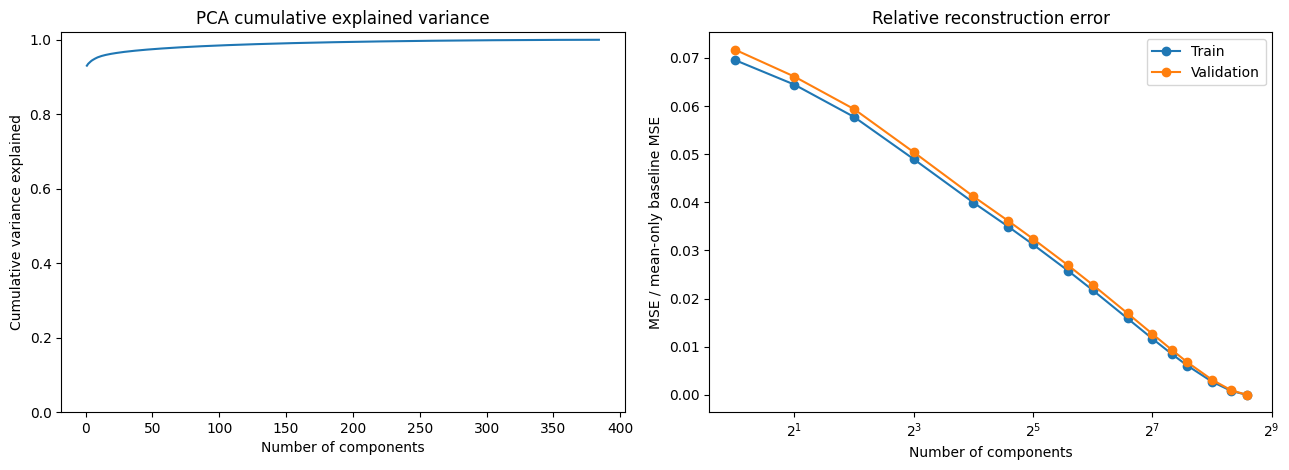

 n_components cumulative_variance_explained   train_mse validation_mse validation_mse_se  train_relative_mse_to_mean_baseline validation_relative_mse_to_mean_baseline
            1                        0.9304  0.00650924     0.00652487          4.11e-05                         6.956334e-02                                   0.0717
            2                        0.9356   0.0060301      0.0060139          3.11e-05                         6.444279e-02                                   0.0661
            4                        0.9423  0.00540174     0.00539995           2.8e-05                         5.772761e-02                                   0.0594
            8                        0.9510  0.00458146     0.00458574          2.53e-05                         4.896137e-02                                   0.0504
           16                        0.9601   0.0037375      0.0037489          2.25e-05                         3.994212e-02                                   0.041

In [ ]:
CANDIDATE_K = sorted(set([1, 2, 4, 8, 16, 24, 32, 48, 64, 96, 128, 160, 192, 256, 320, 384]))

scores_train = pca_full.transform(X_train)
scores_val = pca_full.transform(X_val)

train_mean_baseline = float(np.mean((X_train - pca_full.mean_) ** 2))
val_mean_baseline = float(np.mean((X_val - pca_full.mean_) ** 2))


def reconstruct_from_first_k(scores: np.ndarray, pca_model: PCA, k: int) -> np.ndarray:
    """Reconstruct activation vectors using only the first k PCA components."""
    if not (1 <= k <= pca_model.n_components_):
        raise ValueError(f'k must be in [1, {pca_model.n_components_}], got {k}')
    return scores[:, :k] @ pca_model.components_[:k, :] + pca_model.mean_


rows = []
for k in CANDIDATE_K:
    train_recon = reconstruct_from_first_k(scores_train, pca_full, k)
    val_recon = reconstruct_from_first_k(scores_val, pca_full, k)

    train_per_image = np.mean((X_train - train_recon) ** 2, axis=1)
    val_per_image = np.mean((X_val - val_recon) ** 2, axis=1)

    rows.append({
        'n_components': k,
        'cumulative_variance_explained': float(explained[:k].sum()),
        'train_mse': float(train_per_image.mean()),
        'validation_mse': float(val_per_image.mean()),
        'validation_mse_se': float(val_per_image.std(ddof=1) / np.sqrt(len(val_per_image))),
        'train_relative_mse_to_mean_baseline': float(train_per_image.mean() / train_mean_baseline),
        'validation_relative_mse_to_mean_baseline': float(val_per_image.mean() / val_mean_baseline),
    })

component_metrics = pd.DataFrame(rows)
component_metrics.to_csv(RUN_DIR / 'pca_component_retention_metrics.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(np.arange(1, EXPECTED_D + 1), np.cumsum(explained))
axes[0].set_title('PCA cumulative explained variance')
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('Cumulative variance explained')
axes[0].set_ylim(0, 1.02)
axes[1].plot(component_metrics['n_components'], component_metrics['train_relative_mse_to_mean_baseline'], marker='o', label='Train')
axes[1].plot(component_metrics['n_components'], component_metrics['validation_relative_mse_to_mean_baseline'], marker='o', label='Validation')
axes[1].set_title('Relative reconstruction error')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('MSE / mean-only baseline MSE')
axes[1].set_xscale('log', base=2)
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_variance_and_reconstruction.png', dpi=180, bbox_inches='tight')
plt.show()

print(component_metrics.to_string(index=False, formatters={
    'cumulative_variance_explained': '{:.4f}'.format,
    'train_mse': '{:.6g}'.format,
    'validation_mse': '{:.6g}'.format,
    'validation_mse_se': '{:.3g}'.format,
    'validation_relative_mse_to_mean_baseline': '{:.4f}'.format,
}))
print('\nSaved component-retention metrics and figure.')

## 6. Select and record a component count

Inspect the table and curves above. Choose a component count based primarily on validation reconstruction and the scientific role of PCA as a compact linear baseline. Record the rationale in `SELECTION_RATIONALE`.

The chosen value is a methodological decision; it is intentionally not guessed by this notebook before its validation results have been seen.

In [ ]:
# After reviewing the validation results, replace None with the selected integer.
SELECTED_N_COMPONENTS = 16  # Selected for high parsimoniousness and capturing 96.01% of the variance.
SELECTION_RATIONALE = (
    "Selected k=16 components because it offers a highly parsimonious linear representation "
    "(retaining only 4.2% of the original 384 dimensions) while capturing 96.01% of the cumulative "
    "variance and reducing validation reconstruction MSE to 4.12% of the mean-only baseline."
)

if SELECTED_N_COMPONENTS is None:
    print('Component selection is still pending.')
    print('Review pca_component_retention_metrics.csv and set SELECTED_N_COMPONENTS and SELECTION_RATIONALE.')
else:
    assert isinstance(SELECTED_N_COMPONENTS, int)
    assert SELECTED_N_COMPONENTS in CANDIDATE_K
    assert SELECTED_N_COMPONENTS <= EXPECTED_D
    assert SELECTION_RATIONALE.strip(), 'Record the rationale for the selected component count.'
    print('Selected components:', SELECTED_N_COMPONENTS)
    print('Rationale:', SELECTION_RATIONALE)

Selected components: 16
Rationale: Selected k=16 components because it offers a highly parsimonious linear representation (retaining only 4.2% of the original 384 dimensions) while capturing 96.01% of the cumulative variance and reducing validation reconstruction MSE to 4.12% of the mean-only baseline.


## 7. Development-only Feather projection

This section is conditional on choosing `SELECTED_N_COMPONENTS` above. It loads the Feather activation arrays as memory maps, then indexes **only the eight development samples** using the activation metadata. It does not read primary-evaluation or reserve rows.

The same frozen PCA model is applied to source, standard-metamer, and adversarial-metamer vectors. No condition-specific PCA is fitted.

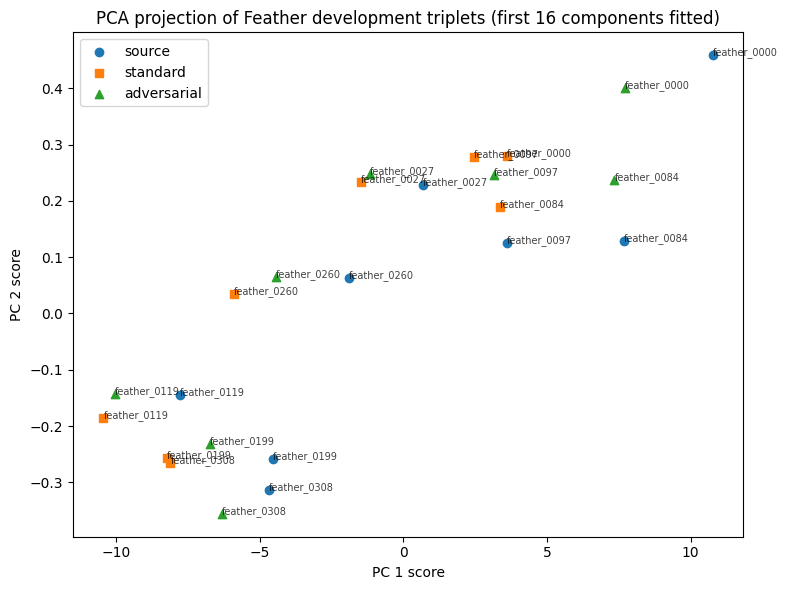

Development samples: ['feather_0000', 'feather_0027', 'feather_0084', 'feather_0097', 'feather_0119', 'feather_0199', 'feather_0260', 'feather_0308']
       source_to_standard_l2  source_to_adversarial_l2
count                8.00000                   8.00000
mean                 3.59386                   1.82735
std                  1.78518                   0.91869
min                  1.19770                   0.49724
25%                  2.56869                   1.36071
50%                  3.56689                   2.02911
75%                  4.09586                   2.35149
max                  7.19674                   3.06009

Saved development-only embeddings and paired-distance diagnostics.


In [ ]:
if SELECTED_N_COMPONENTS is None:
    print('Skipping Feather projection until a component count has been selected.')
else:
    def feather_sample_id(filename: str) -> str:
        # Notebook 03's diagnostic code uses the first two filename tokens (e.g. feather_0000).
        return '_'.join(Path(str(filename)).stem.split('_')[:2])

    feather_meta = {}
    feather_arrays = {}
    development_ids = None

    for condition, directory in FEATHER_DIRS.items():
        metadata_path = directory / 'metadata.csv'
        pooled_path = directory / 'pooled_activations.npy'
        assert metadata_path.is_file(), metadata_path
        assert pooled_path.is_file(), pooled_path

        meta = pd.read_csv(metadata_path)
        pooled = np.load(pooled_path, mmap_mode='r', allow_pickle=False)

        assert pooled.shape == (48, EXPECTED_D), (condition, pooled.shape)
        assert pooled.dtype == np.float32, (condition, pooled.dtype)
        assert {'activation_index', 'split', 'filename'}.issubset(meta.columns)
        assert meta['activation_index'].tolist() == list(range(48))

        meta = meta.copy()
        meta['sample_id'] = meta['filename'].map(feather_sample_id)
        dev_meta = meta.loc[meta['split'].astype(str).eq('development')].copy()
        assert len(dev_meta) == 8, (condition, len(dev_meta))
        assert dev_meta['sample_id'].is_unique

        current_ids = sorted(dev_meta['sample_id'].tolist())
        if development_ids is None:
            development_ids = current_ids
        else:
            assert current_ids == development_ids, f'Development sample IDs differ for {condition}'

        feather_meta[condition] = dev_meta.set_index('sample_id').loc[development_ids]
        feather_arrays[condition] = pooled

    # All three stimulus conditions must share exactly the same 8 development IDs.
    assert development_ids is not None and len(development_ids) == 8

    projected_rows = []
    projected_by_condition = {}

    for condition in ('source', 'standard', 'adversarial'):
        meta = feather_meta[condition]
        row_indices = meta['activation_index'].astype(int).to_numpy()
        X_dev = np.asarray(feather_arrays[condition][row_indices], dtype=np.float32)
        assert X_dev.shape == (8, EXPECTED_D)
        assert np.isfinite(X_dev).all()

        scores = pca_full.transform(X_dev)[:, :SELECTED_N_COMPONENTS]
        projected_by_condition[condition] = scores

        for i, sample_id in enumerate(development_ids):
            row = {
                'sample_id': sample_id,
                'condition': condition,
                'activation_index': int(row_indices[i]),
                'pc1': float(scores[i, 0]),
                'pc2': float(scores[i, 1]) if SELECTED_N_COMPONENTS >= 2 else np.nan,
            }
            for j, value in enumerate(scores[i], start=1):
                row[f'pc{j}'] = float(value)
            projected_rows.append(row)

    dev_embeddings = pd.DataFrame(projected_rows)
    dev_embeddings.to_csv(RUN_DIR / 'pca_development_embeddings.csv', index=False)

    # Descriptive paired distances for the development set only.
    pair_rows = []
    for i, sample_id in enumerate(development_ids):
        source_score = projected_by_condition['source'][i]
        standard_score = projected_by_condition['standard'][i]
        adversarial_score = projected_by_condition['adversarial'][i]
        pair_rows.append({
            'sample_id': sample_id,
            'source_to_standard_l2': float(np.linalg.norm(standard_score - source_score)),
            'source_to_adversarial_l2': float(np.linalg.norm(adversarial_score - source_score)),
        })

    dev_pair_metrics = pd.DataFrame(pair_rows)
    dev_pair_metrics.to_csv(RUN_DIR / 'pca_development_pair_distances.csv', index=False)

    if SELECTED_N_COMPONENTS >= 2:
        fig, ax = plt.subplots(figsize=(8, 6))
        marker_by_condition = {'source': 'o', 'standard': 's', 'adversarial': '^'}
        for condition in ('source', 'standard', 'adversarial'):
            scores = projected_by_condition[condition]
            ax.scatter(scores[:, 0], scores[:, 1], marker=marker_by_condition[condition], label=condition)
            for i, sample_id in enumerate(development_ids):
                ax.annotate(sample_id, (scores[i, 0], scores[i, 1]), fontsize=7, alpha=0.75)
        ax.set_title(f'PCA projection of Feather development triplets (first {SELECTED_N_COMPONENTS} components fitted)')
        ax.set_xlabel('PC 1 score')
        ax.set_ylabel('PC 2 score')
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURE_DIR / 'pca_development_projection_pc1_pc2.png', dpi=180, bbox_inches='tight')
        plt.show()
    else:
        print('Selected PCA dimension is 1; skipping the two-dimensional PC1–PC2 plot.')

    print('Development samples:', development_ids)
    print(dev_pair_metrics.describe().round(5).to_string())
    print('\nSaved development-only embeddings and paired-distance diagnostics.')

## 8. Save configuration and reproducibility record

The full 384-component PCA object is retained so later notebooks can apply exactly the same fitted basis and select the recorded leading `k` components. The configuration records the data split used for fitting, centring/scaling choice, software versions, and hashes of the input activation files.

Primary-evaluation and reserve activations are not read by this notebook.

In [ ]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as file:
        for chunk in iter(lambda: file.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

config = {
    'run_id': RUN_ID,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'project': 'Metamer-SAE',
    'notebook': '04_pca_analysis.ipynb',
    'observer': 'TorchVision ConvNeXt-Tiny, ImageNet1K_V1',
    'observer_activation': 'stage 3, global-average-pooled, 384 dimensions',
    'fit_dataset': 'Imagenette-320 training split only',
    'fit_sample_count': int(X_train.shape[0]),
    'validation_dataset': 'Imagenette-320 validation split only',
    'validation_sample_count': int(X_val.shape[0]),
    'input_dimensions': int(EXPECTED_D),
    'pca_components_fitted': int(pca_full.n_components_),
    'selected_components': SELECTED_N_COMPONENTS,
    'selection_rationale': SELECTION_RATIONALE,
    'solver': 'full',
    'whiten': False,
    'feature_scaling': 'none; PCA performs mean centring using Imagenette train mean',
    'fit_data_path': str(TRAIN_ARRAY_PATH),
    'validation_data_path': str(VAL_ARRAY_PATH),
    'fit_activation_sha256': sha256_file(TRAIN_ARRAY_PATH),
    'validation_activation_sha256': sha256_file(VAL_ARRAY_PATH),
    'train_metadata_sha256': sha256_file(TRAIN_METADATA_PATH),
    'validation_metadata_sha256': sha256_file(VAL_METADATA_PATH),
    'python': sys.version,
    'platform': platform.platform(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__,
    'joblib': joblib.__version__,
    'primary_evaluation_loaded': False,
    'reserve_loaded': False,
    'human_behaviour_loaded': False,
}

with (RUN_DIR / 'pca_run_config.json').open('w', encoding='utf-8') as file:
    json.dump(config, file, indent=2)

print(json.dumps(config, indent=2))
print('\nRun artifacts written to:', RUN_DIR)

{
  "run_id": "pca_20261119T065920Z",
  "created_utc": "2026-11-19T07:07:25.690850+00:00",
  "project": "Metamer-SAE",
  "notebook": "04_pca_analysis.ipynb",
  "observer": "TorchVision ConvNeXt-Tiny, ImageNet1K_V1",
  "observer_activation": "stage 3, global-average-pooled, 384 dimensions",
  "fit_dataset": "Imagenette-320 training split only",
  "fit_sample_count": 9469,
  "validation_dataset": "Imagenette-320 validation split only",
  "validation_sample_count": 3925,
  "input_dimensions": 384,
  "pca_components_fitted": 384,
  "selected_components": 16,
  "selection_rationale": "Selected k=16 components because it offers a highly parsimonious linear representation (retaining only 4.2% of the original 384 dimensions) while capturing 96.01% of the cumulative variance and reducing validation reconstruction MSE to 4.12% of the mean-only baseline.",
  "solver": "full",
  "whiten": false,
  "feature_scaling": "none; PCA performs mean centring using Imagenette train mean",
  "fit_data_path":

## 9. Notebook 04 completion checklist

Before closing this notebook, confirm:

- [ ] PCA was fitted on Imagenette train only.
- [ ] Imagenette validation was used only for model assessment and component selection.
- [ ] The component count and its rationale are recorded.
- [ ] Feather development was projected with the same fitted PCA model.
- [ ] Primary-evaluation and reserve data were not accessed.
- [ ] The PCA object, metrics, figures, and run configuration are saved in the run folder.
- [ ] The next notebook can load the saved PCA object and reproduce the development transform.

### Handoff to the next stage

The next stage should use the selected PCA setting as the linear baseline and prepare the natural-image activation interface for the Overcomplete TopK SAE. Before training the SAE, inspect and pin the actual Overcomplete version and validate its Python compatibility and import/API path. The recorded Notebook 03 runtime used Python 3.13, while the inspected Overcomplete `pyproject.toml` specifies `python = ">=3.8,<3.13"`; do not assume it will install in that runtime.